<a href="https://colab.research.google.com/github/byuruth/Econ484/blob/main/pset5coding_ruthwright.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import the modules and function you will use here
import pandas as pd
!git clone https://github.com/byuruth/Econ484.git
%cd Econ484/data
import warnings
warnings.filterwarnings('ignore')

Cloning into 'Econ484'...
remote: Enumerating objects: 282, done.
remote: Counting objects: 100% (105/105), done.
remote: Compressing objects: 100% (97/97), done.
remote: Total 282 (delta 67), reused 8 (delta 8), pack-reused 177 (from 1)
Receiving objects: 100% (282/282), 14.11 MiB | 9.55 MiB/s, done.
Resolving deltas: 100% (102/102), done.
/content/Econ484/data


This problem deals with regularized regression. The California Housing dataset is described right after it is loaded in just by running the code that is already there.

In [2]:
from sklearn.datasets import fetch_california_housing
import numpy as np
import pandas as pd
housing = fetch_california_housing()
print(housing['DESCR'])
#Define X and y
X = pd.DataFrame(housing['data'], columns=housing['feature_names'])
y = pd.Series(housing['target'])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [3]:
display(X.head())
display(y.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


,0
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


$(a)$ Split the data into a train and a test set

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y)

$(b)$ Use this data to fit an OLS, LASSO, ridge, and ElasticNet model on the data. For now, use the default for the penalty coefficient. Display the coefficients and test error for each.

In [5]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_squared_error
lasso = Lasso().fit(X_train,y_train)
lasso_pred = lasso.predict(X_test)
print(f"The coefficients on lasso are:\n {lasso.coef_}\n")
print(f"The mean sqauared error is: {mean_squared_error(y_test,lasso_pred)}. And this is really cool.")
ridge = Ridge().fit(X_train,y_train)
ridge_pred = ridge.predict(X_test)
print(f"The coefficients on ridge are:\n {ridge.coef_}\n")
print(f"The mean sqauared error is: {mean_squared_error(y_test,ridge_pred)}")
elastic = ElasticNet().fit(X_train,y_train)
elastic_pred = elastic.predict(X_test)
print(f"The coefficients on elastic are:\n {elastic.coef_}\n")
print(f"The mean sqauared error is: {mean_squared_error(y_test,elastic_pred)}")
from sklearn.linear_model import LinearRegression
ols = LinearRegression().fit(X_train,y_train)
ols_pred = ols.predict(X_test)
print(f"The coefficients on ols are:\n {ols.coef_}\n")
print(f"The mean sqauared error is: {mean_squared_error(y_test,ols_pred)}")

The coefficients on lasso are:
 [ 1.43634582e-01  5.76715047e-03  0.00000000e+00 -0.00000000e+00
 -5.74313658e-06 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00]

The mean sqauared error is: 0.9471642287132782. And this is really cool.
The coefficients on ridge are:
 [ 4.32279260e-01  9.23695101e-03 -1.02511792e-01  6.27424487e-01
 -4.61485944e-06 -3.40610842e-03 -4.25838993e-01 -4.38069312e-01]

The mean sqauared error is: 0.509563222594905
The coefficients on elastic are:
 [ 2.51665479e-01  1.11810586e-02  0.00000000e+00 -0.00000000e+00
  9.29797622e-06 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00]

The mean sqauared error is: 0.7576733582943125
The coefficients on ols are:
 [ 4.32408086e-01  9.23470087e-03 -1.02759549e-01  6.28732699e-01
 -4.62318983e-06 -3.40640147e-03 -4.25859512e-01 -4.38108474e-01]

The mean sqauared error is: 0.5095583982355495


$(c)$ Describe the differences that you see in the coefficients and error. What is the cause of this difference in coefficients?

Some of the Lasso and Elastic Net coefficients are shrunk to zero while the Ridge ones are not. The penalty for Lasso is the sum of lambda |b| while the penalty for Ridge is the sum of lambda $b^2$. This is because Lasso imposes a bigger penalty on small coefficients and will shrink them to zero when they do not add additional explanatory power relative to the MSE

$(d)$ Use K-fold cross validation to find an optimal penalty parameter for Ridge and Lasso. This will take forever if you use all the observations in the housing dataset. For the purpose of this assignment, you can use a random subsample to make it go faster. You may use the subsample througout the rest of the assignment when you need to perform cross validation.

In [6]:
chosen_idx = np.random.choice(len(X.index), replace=False, size = 500)
sub_X = X.iloc[chosen_idx]
sub_y = y.iloc[chosen_idx]

In [7]:
from sklearn.model_selection import GridSearchCV
alpha_grid = {'alpha': [.0001,.001,.002, .004, .006, .008, .01, .012, .014, .016 ,.018, .02 ],'max_iter': [100000]}
ridge_cv = GridSearchCV(Ridge(), alpha_grid, cv=5).fit(sub_X, sub_y)
lasso_cv = GridSearchCV(Lasso(), alpha_grid, cv=5).fit(sub_X, sub_y)
print("Best Ridge alpha: ",ridge_cv.best_estimator_.get_params()['alpha'])
print("Best Lasso alpha: ",lasso_cv.best_estimator_.get_params()['alpha'])


Best Ridge alpha:  0.02
Best Lasso alpha:  0.016


$(e)$ Now use cross validation, to find the optimal penalty parameter. Use LOOCV and Kfold cross validation with K=5 to find optimal parameters for the ElasticNet model. How do the test errors and optimal parameters differ?

In [8]:
from sklearn.model_selection import LeaveOneOut
alpha_grid = {'alpha': [.0001,.001,.002, .004, .006, .008, .01, .012, .014, .016 ,.018, .02 ],'max_iter': [100000]}
elastic_loo = GridSearchCV(ElasticNet(l1_ratio=.5), alpha_grid, cv=LeaveOneOut()).fit(sub_X, sub_y)
elastic_5 = GridSearchCV(ElasticNet(l1_ratio=.5), alpha_grid, cv=5).fit(sub_X, sub_y)
print("Best LOOCV alpha: ",elastic_loo.best_estimator_.get_params()['alpha'])
print("Best Kfold alpha: ",elastic_5.best_estimator_.get_params()['alpha'])
print("LOOCV test MSE:", mean_squared_error(y_test, elastic_loo.predict(X_test)))
print("Kfold test MSE:", mean_squared_error(y_test, elastic_5.predict(X_test)))

Best LOOCV alpha:  0.0001
Best Kfold alpha:  0.02
LOOCV test MSE: 1.2843215114270212
Kfold test MSE: 1.2464923874255316


$(f)$ Now that we have tuned the models to perform about as well as they can, which one performs best on the training data? Which one performs best on the test data? Which of these models allow us to do effective causal inference with the coefficients? Why?

In [ ]:
models = {
    'OLS': ols,
    'Ridge': ridge_cv.best_estimator_,
    'Lasso': lasso_cv.best_estimator_,
    'ElasticNet': elastic_5.best_estimator_
}

for name, model in models.items():
    train_mse = mean_squared_error(sub_y, model.predict(sub_X))
    test_mse = mean_squared_error(y_test, model.predict(X_test))

    print(f"{name}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}")

OLS: Train MSE = 0.5683, Test MSE = 0.5246
Ridge: Train MSE = 0.5071, Test MSE = 0.5063
Lasso: Train MSE = 0.5169, Test MSE = 0.5211
ElasticNet: Train MSE = 0.5087, Test MSE = 0.5101


OLS does best on the training data and the test data. This model is also the best for effective causal inference if the identification assumptuions hold and the coefficients are the most interpretable.

For the next problem we will be using the `Carseats` data set that is available on learningsuite. Load the data and convert the text variables into dummies so that we can use them in the data. Pandas has a function called `get_dummies` that you might want to use.

In [10]:
carseats = pd.read_csv("Carseats.csv")
carseats = pd.get_dummies(carseats, drop_first=True)
carseats.head()

,Unnamed: 0,Sales,CompPrice,Income,Advertising,Population,Price,Age,Education,ShelveLoc_Good,ShelveLoc_Medium,Urban_Yes,US_Yes
0,1,9.50,138,73,11,276,120,42,17,False,False,True,True
1,2,11.22,111,48,16,260,83,65,10,True,False,True,True
2,3,10.06,113,35,10,269,80,59,12,False,True,True,True
3,4,7.40,117,100,4,466,97,55,14,False,True,True,True
4,5,4.15,141,64,3,340,128,38,13,False,False,True,False


Now that the data has only numeric columns, we can proceed to the analysis.  
Use `Sales` as the outcome variable  
(a) Split the data set into a training set and a test set.  
(b) Fit a regression tree to the training set with the default depth. What train and test MSE do you obtain?  
(c) Use cross-validation in order to determine the optimal level of tree complexity. Does pruning the tree improve the test MSE? Plot a tree with a depth of 3, and interpret the results.  
(d) Use a bagging approach in order to analyze this data. What test MSE do you obtain? Look at the feature importances attribute of your model object to determine which variables are most important.  
(e) Use random forests to analyze this data. What test MSE do you obtain? Look at the feature importances attribute of your model object function to determine which variables are most important. Describe the effect of m, the number of variables considered at each split, on the error rate obtained.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(carseats.drop('Sales', axis=1), carseats['Sales'])

In [15]:
from sklearn.tree import DecisionTreeRegressor
tree = DecisionTreeRegressor().fit(X_train, y_train)
print("Train MSE:", mean_squared_error(y_train, tree.predict(X_train)))
print("Test MSE:", mean_squared_error(y_test, tree.predict(X_test)))

Train MSE: 0.0
Test MSE: 5.993302


Best depth:  6
Original tree test MSE:  5.993302
Pruned tree test MSE:  4.751377633486241


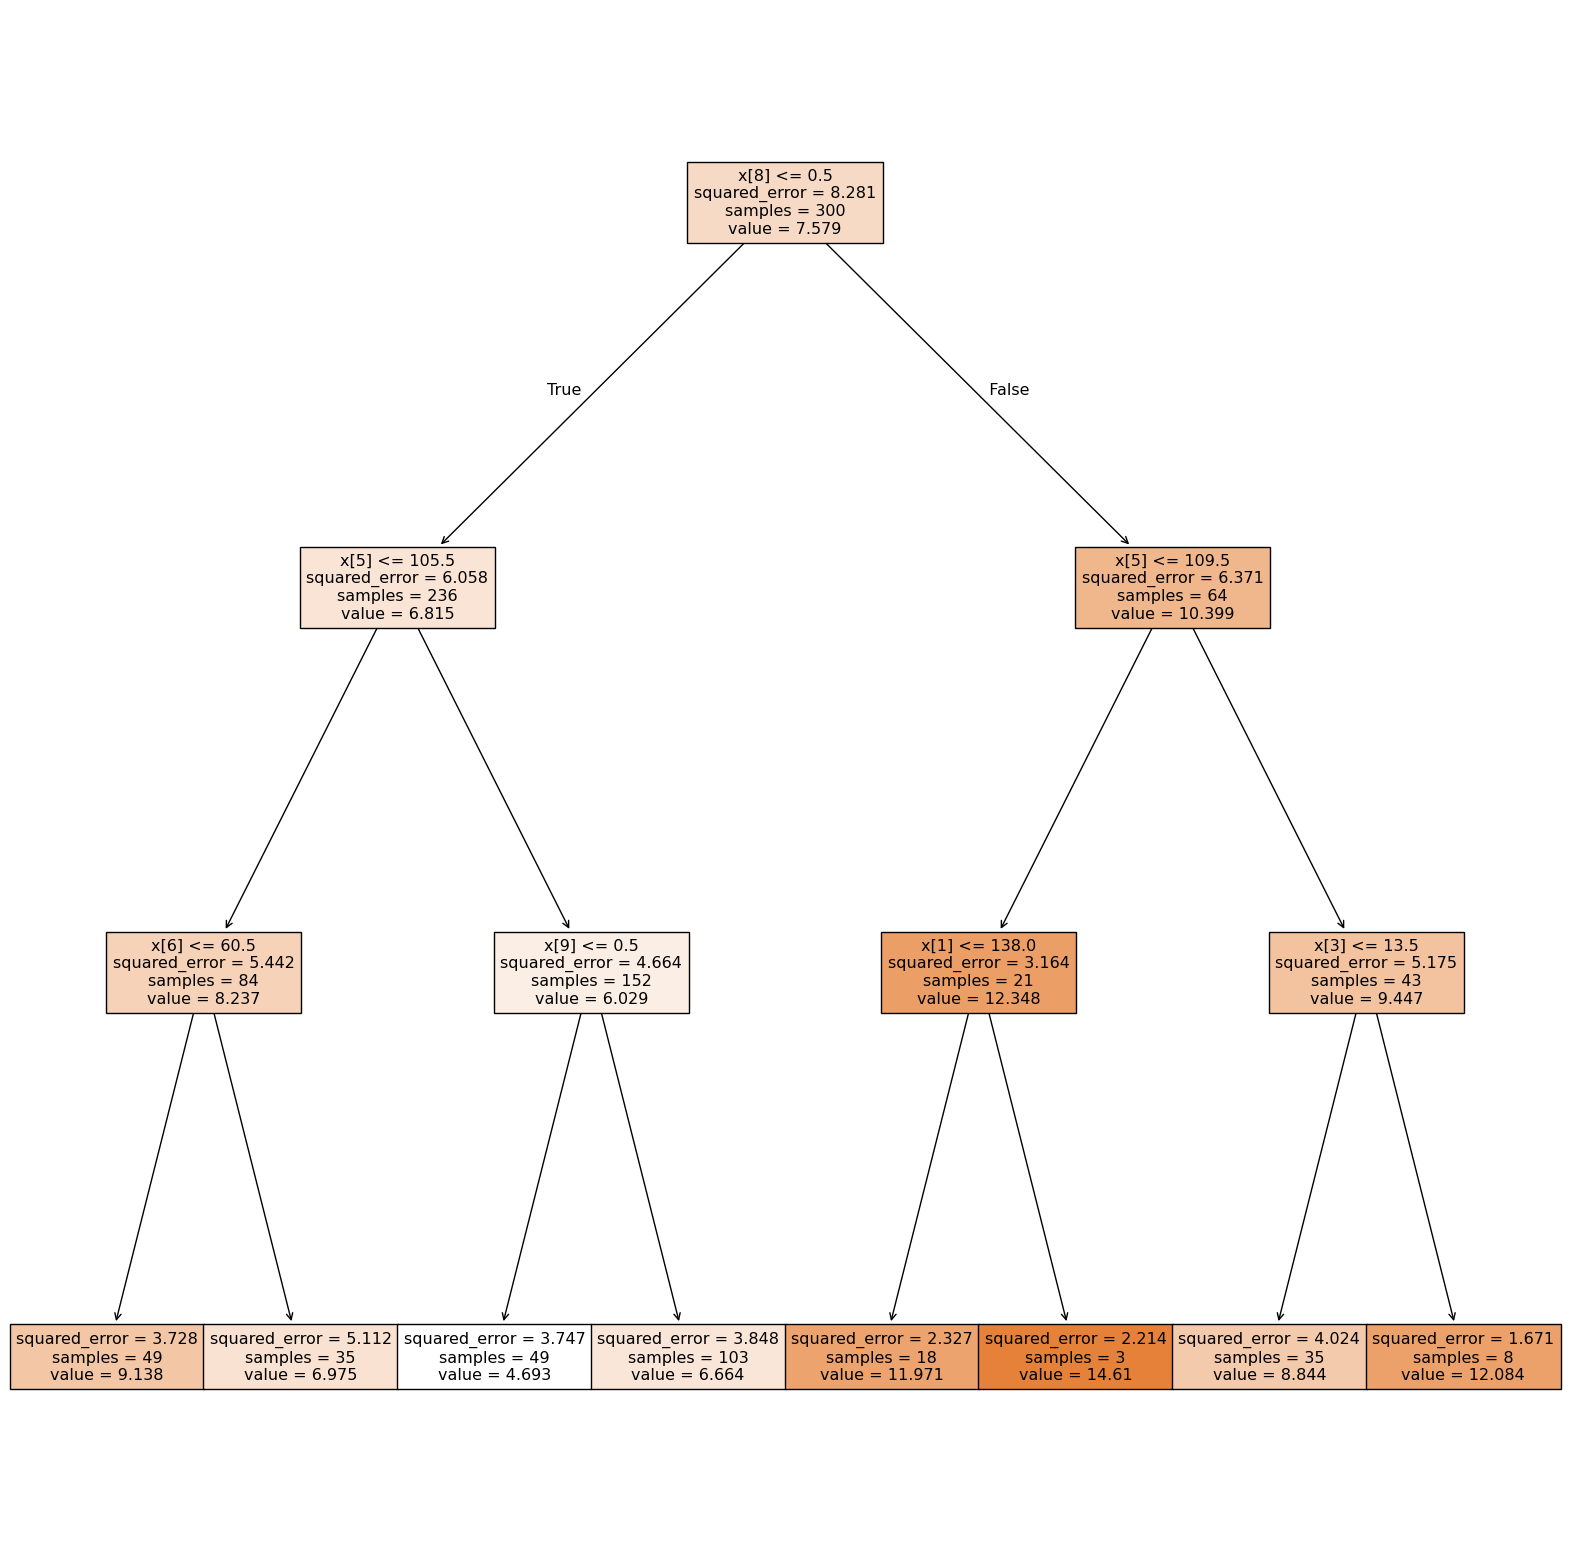

In [17]:
tree_cv = GridSearchCV(DecisionTreeRegressor(), {'max_depth': range(1,10)}, cv=5).fit(X_train, y_train)
print("Best depth: ",tree_cv.best_estimator_.get_params()['max_depth'])

pruned_tree = DecisionTreeRegressor(max_depth=tree_cv.best_estimator_.get_params()['max_depth']).fit(X_train, y_train)
print("Original tree test MSE: ", mean_squared_error(y_test, tree.predict(X_test)))
print("Pruned tree test MSE: ", mean_squared_error(y_test, pruned_tree.predict(X_test)))

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
tree3 = DecisionTreeRegressor(max_depth=3).fit(X_train, y_train)
plt.figure(figsize=(20,20))
plot_tree(tree3, filled=True)
plt.show()

Using 5-fold CV, I found that the optimal tree depth was 6. Pruning the tree improved the predictive performance as it decreased the MSE. The tree divides observations into groups based on their explanatory variables, and each split reduces the variation in sales. The values at the terminal nodes are the predicted sales for those observations.

In [20]:
from sklearn.ensemble import BaggingRegressor
bagged_tree = BaggingRegressor(DecisionTreeRegressor(), n_estimators=100).fit(X_train, y_train)
print("Bagged tree test MSE: ", mean_squared_error(y_test, bagged_tree.predict(X_test)))
print("Bagged tree feature importances: ", bagged_tree.estimators_[0].feature_importances_)

Bagged tree test MSE:  2.2856124695
Bagged tree feature importances:  [0.01761056 0.0908578  0.05421372 0.0848894  0.02079977 0.27273787
 0.14873255 0.01705729 0.24831366 0.03867078 0.00475694 0.00135968]


In [23]:
from sklearn.ensemble import RandomForestRegressor
random_forest = RandomForestRegressor(n_estimators=100).fit(X_train, y_train)
print("Random forest test MSE: ", mean_squared_error(y_test, random_forest.predict(X_test)))
print("Random forest feature importances: ", random_forest.feature_importances_)


m_values = range(1, X_train.shape[1] + 1)
mse_values = []

for m in m_values:
    rf_m = RandomForestRegressor(
        n_estimators=100,
        max_features=m,
        random_state=42
    ).fit(X_train, y_train)

    pred = rf_m.predict(X_test)
    mse_values.append(mean_squared_error(y_test, pred))

for m, mse in zip(m_values, mse_values):
    print(f"m = {m}, Test MSE = {mse:.4f}")

print("Best m:", list(m_values)[np.argmin(mse_values)])

Random forest test MSE:  2.3174525641000003
Random forest feature importances:  [0.03697616 0.08729592 0.05425797 0.07496909 0.0341834  0.27677326
 0.08372362 0.02053157 0.26587234 0.05636738 0.0041555  0.00489379]
m = 1, Test MSE = 3.7177
m = 2, Test MSE = 2.9591
m = 3, Test MSE = 2.5994
m = 4, Test MSE = 2.4896
m = 5, Test MSE = 2.3503
m = 6, Test MSE = 2.3409
m = 7, Test MSE = 2.3539
m = 8, Test MSE = 2.2716
m = 9, Test MSE = 2.2749
m = 10, Test MSE = 2.2826
m = 11, Test MSE = 2.2614
m = 12, Test MSE = 2.1642
Best m: 12


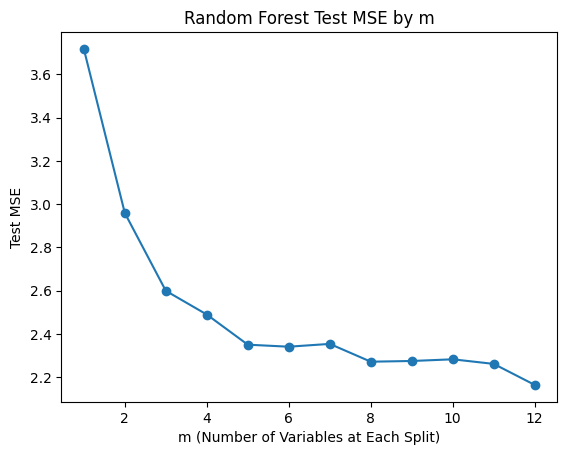

In [24]:

plt.plot(m_values, mse_values, marker='o')
plt.xlabel("m (Number of Variables at Each Split)")
plt.ylabel("Test MSE")
plt.title("Random Forest Test MSE by m")
plt.show()


Changing m affects the number of predictors considered at each split. Smaller values of m increawse randomness and reduce correlation between trees, potentially lowering test MSE. However, if m is too small, the trees may become less accurate.

We will now use boosting to predict Log Salary in the `Hitters` data set.  
(a) Format the data appropriately for this analysis. Use 200 observations in your training set.  
(b) Perform boosting on the training set with 1,000 trees for a range of values of the shrinkage parameter λ. Produce a plot with different shrinkage values on the x-axis and the corresponding training set MSE on the y-axis. Add a curve with different shrinkage values on the x-axis and the corresponding test set MSE on the y-axis. The shrinkage parameter is often referred to as the learning rate   
(c) Compare the test MSE of boosting to the test MSE of two of the penalized regression approaches that we discussed  
(d) Which variables appear to be the most important predictors in the boosted model?  
(e) The default for base estimator is a Decision Tree with a maximum depth of 3. Is that the optimal depth? Justify your response.  
(f) Now that the boosting model is tuned, let's compare the results to bagging and random forests. Report test errors for your models and discuss how they compare.

In [26]:
hitters = pd.read_csv("Hitters.csv").dropna()
hitters = pd.get_dummies(hitters, drop_first=True)
hitters.head()
hitters['LogSalary'] = np.log(hitters['Salary'])
hitters = hitters.drop('Salary', axis=1)
y = hitters['LogSalary']
X = hitters
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 200, random_state=42)

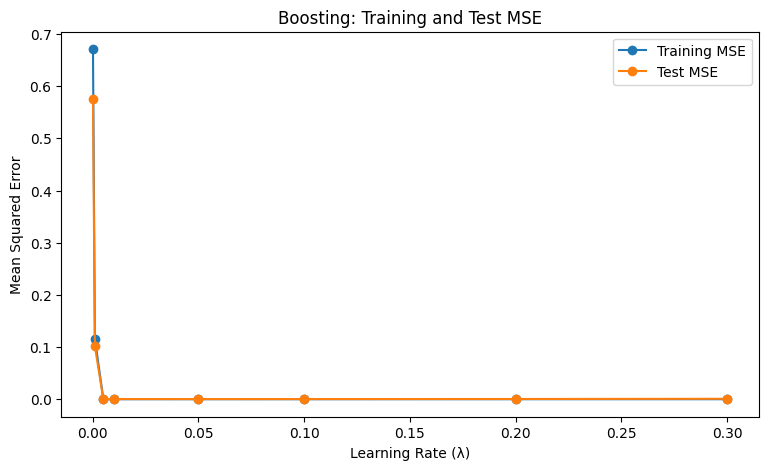

In [28]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
learning_rates = [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3]
train_mse = []
test_mse = []

for lr in learning_rates:
    boost = GradientBoostingRegressor(
        n_estimators=1000,
        learning_rate=lr,
        random_state=42
    )

    boost.fit(X_train, y_train)

    train_pred = boost.predict(X_train)
    test_pred = boost.predict(X_test)

    train_mse.append(mean_squared_error(y_train, train_pred))
    test_mse.append(mean_squared_error(y_test, test_pred))


plt.figure(figsize=(9, 5))

plt.plot(learning_rates, train_mse, marker='o', label='Training MSE')
plt.plot(learning_rates, test_mse, marker='o', label='Test MSE')

plt.xlabel('Learning Rate (λ)')
plt.ylabel('Mean Squared Error')
plt.title('Boosting: Training and Test MSE')
plt.legend()
plt.show()



In [31]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error

alpha_grid = {'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}
lasso_cv = GridSearchCV(Lasso(max_iter=100000), alpha_grid, cv=5).fit(X_train, y_train)
ridge_cv = GridSearchCV(Ridge(), alpha_grid, cv=5).fit(X_train, y_train)

print("Test MSE for Lasso: ", mean_squared_error(y_test, lasso_cv.predict(X_test)))
print("Test MSE for Ridge: ", mean_squared_error(y_test, ridge_cv.predict(X_test)))
test_mse

Test MSE for Lasso:  3.145090155075208e-08
Test MSE for Ridge:  1.0443080457301956e-12


[0.5749556148581996,
 0.101345889544447,
 0.0003286525432596239,
 0.0003111401694482674,
 0.00027411817890049246,
 0.000296347844092188,
 0.00044816404203045304,
 0.0008390413607536762]

In [32]:
importance = pd.Series(boost.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importance)

LogSalary      9.993562e-01
CRBI           1.195903e-04
CHmRun         1.142796e-04
Walks          9.143867e-05
Errors         5.813236e-05
CHits          3.799664e-05
PutOuts        3.308646e-05
Hits           3.302776e-05
Assists        3.286028e-05
RBI            2.531883e-05
AtBat          2.424152e-05
Runs           1.924407e-05
CAtBat         1.468589e-05
CWalks         1.229254e-05
Years          9.379600e-06
CRuns          8.078737e-06
HmRun          7.084192e-06
Division_W     1.373673e-06
NewLeague_N    1.003143e-06
League_N       6.712413e-07
dtype: float64


In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
best_lr = learning_rates[np.argmin(test_mse)]
print("Best learning rate:", best_lr)

depth_grid = {'max_depth': range(1, 11)}
boost_cv = GridSearchCV(GradientBoostingRegressor(n_estimators=1000, learning_rate=best_lr, random_state=42),depth_grid,cv=5,scoring='neg_mean_squared_error').fit(X_train, y_train)
print("Best depth:", boost_cv.best_params_['max_depth'])


default_boost = GradientBoostingRegressor(n_estimators=1000, learning_rate=best_lr, max_depth=3, random_state=42).fit(X_train, y_train)
best_boost = boost_cv.best_estimator_

print("Depth 3 Test MSE:",mean_squared_error(y_test, default_boost.predict(X_test)))
print("Optimal Depth Test MSE:", mean_squared_error(y_test, best_boost.predict(X_test)))


Best learning rate: 0.05
Best depth: 2


To test if 3 was the optimal depth i used CV and tested other maximum depths from 1 to 10 while holding the number of trees and learning rate constant. The optial depth was 2, which is less than the default depth

In [35]:
boost_tuned = boost_cv.best_estimator_
bagging = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=100,random_state=42).fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=100, max_features="sqrt",random_state=42).fit(X_train, y_train)

boost_mse = mean_squared_error(y_test, boost_tuned.predict(X_test))
bagging_mse = mean_squared_error(y_test, bagging.predict(X_test))
rf_mse = mean_squared_error(y_test, rf.predict(X_test))

print("Tuned Boosting Test MSE:", boost_mse)
print("Bagging Test MSE:", bagging_mse)
print("Random Forest Test MSE:", rf_mse)


Tuned Boosting Test MSE: 0.0002593388112868561
Bagging Test MSE: 0.0007382976934920244
Random Forest Test MSE: 0.11186329074348321


It looks like the MSE for the random forest did way worse than the boosting  and bagging test.

In this problem, you will use support vector approaches in order to predict whether a given car gets high or low gas mileage based on the Auto data set.  

#### NOTE: SVM algortihms will often take longer than other models to train, particularly when doing cross validation

(a) Create a binary variable that takes on a 1 for cars with gas mileage above the median, and a 0 for cars with gas mileage below the median.  
(b) Fit a support vector classifier to the data with various values of cost, in order to predict whether a car gets high or low gas mileage. Report the cross-validation errors associated with different values of this parameter. Comment on your results.  
(c) Make an ROC curve for your model. The module scikitplot has a nice function you might want to use but you should eb able to make it on your own or another module if you desire.

In [37]:
auto = pd.read_csv("Auto.csv")
auto['high_mileage'] = (auto['mpg'] > auto['mpg'].median()).astype(int)


In [38]:
X = auto.drop(columns=['mpg', 'high_mileage', 'name'])
X = pd.get_dummies(X, drop_first=True)
y = auto['high_mileage']

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

svc = make_pipeline(StandardScaler(), SVC(kernel='linear'))
param_grid = {'svc__C': [0.001, 0.01, 0.1, 1, 10, 100]}
svc_cv = GridSearchCV(svc, param_grid, cv=5, scoring='accuracy').fit(X, y)


results = pd.DataFrame({'C': svc_cv.cv_results_['param_svc__C'],'CV Error': 1 - svc_cv.cv_results_['mean_test_score']})
print(results)
print("Best C:", svc_cv.best_params_['svc__C'])
print("Lowest CV Error:", 1 - svc_cv.best_score_)



         C  CV Error
0    0.001  0.138797
1    0.010  0.151266
2    0.100  0.170918
3    1.000  0.170918
4   10.000  0.173449
5  100.000  0.165918
Best C: 0.001
Lowest CV Error: 0.1387974683544304


The best cost paramater for the SVC was .001 suggesting that it is the best balance between allowing classification errors and penalizing them among the values tested

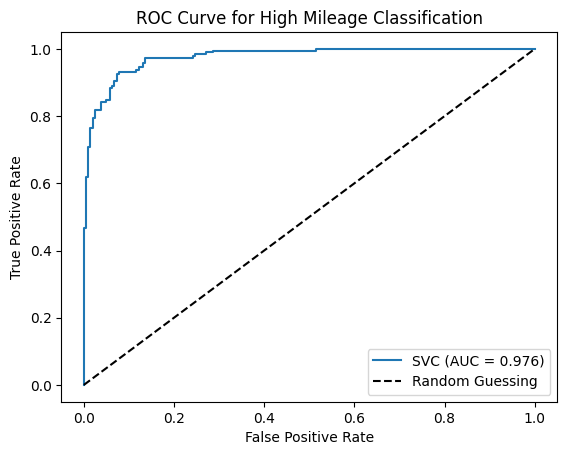

AUC: 0.9761348040461546


In [39]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_scores = svc_cv.best_estimator_.decision_function(X)
fpr, tpr, thresholds = roc_curve(y, y_scores)
auc = roc_auc_score(y, y_scores)

plt.plot(fpr, tpr, label=f'SVC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for High Mileage Classification')
plt.legend()
plt.show()

print("AUC:", auc)


Below there are some generated datasets of varying structure that you will classifying is SVMs, plotting the data to see what it looks like will likey be helpful. Find the basis kernel that does best job classifying each of them. Because the data is two dimensional, it might be nice to use a library like mlxtend which has a function that will display decision regions form an svm using a one of their functions.

In [40]:
from sklearn.datasets import make_moons
x, y = make_moons(n_samples=100, shuffle=True, noise=1/10, random_state=123)

In [41]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

svc = make_pipeline(StandardScaler(), SVC())

param_grid = {'svc__kernel': ['linear', 'poly', 'rbf'],'svc__C': [0.1, 1, 10, 100],'svc__gamma': ['scale', 0.1, 1, 10]}

grid = GridSearchCV(svc, param_grid, cv=5, scoring='accuracy').fit(x, y)

print("Best kernel:", grid.best_params_['svc__kernel'])
print("Best CV accuracy:", grid.best_score_)


Best kernel: rbf
Best CV accuracy: 1.0


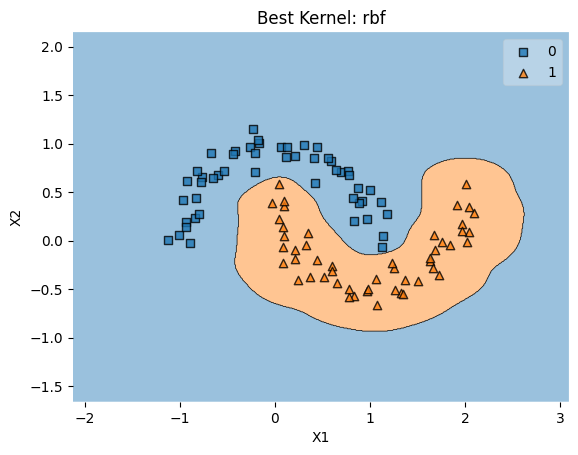

In [42]:
%pip install mlxtend
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

plot_decision_regions(X=x, y=y, clf=grid.best_estimator_)

plt.title(f"Best Kernel: {grid.best_params_['svc__kernel']}")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()


In [46]:
from sklearn.datasets import make_circles
x, y = make_circles(n_samples=100, shuffle=False, noise=1/50, random_state=123, factor=0.6)

In [ ]:
grid.fit(x, y)

print("Best kernel:", grid.best_params_['svc__kernel'])
print("Best CV accuracy:", grid.best_score_)

In [ ]:
%pip install mlxtend
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

plot_decision_regions(X=x, y=y, clf=grid.best_estimator_)

plt.title(f"Best Kernel: {grid.best_params_['svc__kernel']}")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

In [ ]:
from sklearn.datasets import make_blobs
x, y = make_blobs(n_samples=100, n_features=2, centers=None, cluster_std=2.0,
           center_box=(-10.0, 10.0), shuffle=True, random_state=10)

In [ ]:
grid.fit(x, y)

print("Best kernel:", grid.best_params_['svc__kernel'])
print("Best CV accuracy:", grid.best_score_)
